# Лабораторная работа №1 — ноутбук 1/3: EDA и предобработка

## Низкоуровневый анализ, предобработка текста и статистическое языковое моделирование

**Датасет:** [Russian Language Toxic Comments](https://www.kaggle.com/datasets/blackmoon/russian-language-toxic-comments).  
**Текст:** `comment`. **Класс:** `toxic`, где 0 — нетоксичный, 1 — токсичный.  

**Цель:** изучить очистку и нормализацию русского интернет-текста, расстояние редактирования и биграммное языковое моделирование.

### Библиотеки и настройка окружения

Установите зависимости из `requirements.txt`. Поместите Kaggle-файл `labeled.csv` в `data/labeled.csv` рядом с ноутбуками либо настройте доступ к Kaggle через `kagglehub`.

Ноутбуки связаны через папку `artifacts/`: сначала выполните `1_eda.ipynb`, затем `2_metrics.ipynb` и `3_modeling.ipynb`.

In [7]:
import re
import html
import math
from collections import Counter, defaultdict
from functools import lru_cache

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from nltk.stem.snowball import RussianStemmer
from sklearn.model_selection import train_test_split

plt.rcParams.update({"figure.figsize": (10, 4), "font.size": 11})
RNG = np.random.default_rng(42)

# 1. Загрузка данных и разделение Train / Test

используем **80% Train / 20% Test** со стратификацией по бинарному классу. Все решения по EDA и правилам очистки строим на Train; Test нужен только для перплексии.

In [8]:
from pathlib import Path
import numpy as np
import pandas as pd

DATASET_ID = "blackmoon/russian-language-toxic-comments"
SEED = 42

def load_data():
    roots = [Path.cwd(), Path.cwd().parent, Path.cwd() / "data", Path.cwd().parent / "data"]
    paths = [folder / "labeled.csv" for folder in roots]
    paths += [p for folder in roots if folder.exists() for p in folder.glob("*.csv")]
    paths = list(dict.fromkeys(paths))
    files = [p for p in paths if p.is_file()]
    if not files:
        try:
            import kagglehub
            downloaded = Path(kagglehub.dataset_download(DATASET_ID))
            files = sorted(downloaded.rglob("*.csv"), key=lambda p: (p.name != "labeled.csv", str(p)))
        except Exception as exc:
            raise FileNotFoundError(
                "Не найден labeled.csv. Скачайте Kaggle Russian Language Toxic Comments "
                "и поместите data/labeled.csv рядом с ноутбуком (или установите kagglehub "
                "и обеспечьте доступ к Kaggle)."
            ) from exc
    for file in sorted(files, key=lambda p: (p.name != "labeled.csv", str(p))):
        try:
            data = pd.read_csv(file)
        except (UnicodeError, pd.errors.ParserError):
            continue
        if {"comment", "toxic"}.issubset(data.columns):
            data = data[["comment", "toxic"]].copy()
            data["toxic"] = pd.to_numeric(data["toxic"], errors="coerce")
            data = data.dropna(subset=["comment", "toxic"])
            data["comment"] = data["comment"].astype(str)
            data = data[data["comment"].str.strip().ne("")].copy()
            data = data[data["toxic"].isin([0, 1])].copy()
            data["toxic"] = data["toxic"].astype(int)
            if data["toxic"].nunique() != 2:
                raise ValueError("Для стратификации нужны оба класса 0 и 1")
            print("Источник данных:", file)
            return data.reset_index(drop=True)
    raise ValueError("Не найден CSV с колонками comment и toxic")

df = load_data()
print("Форма:", df.shape)
print("Распределение классов:")
print(df["toxic"].value_counts().sort_index().rename(index={0: "нетоксичные", 1: "токсичные"}))
print("Полных дубликатов:", df.duplicated(subset=["comment", "toxic"]).sum())

Источник данных: d:\ITMO\itmo_text_analysis_toxic_lab1_v4\lab1\data\labeled.csv
Форма: (14412, 2)
Распределение классов:
toxic
нетоксичные    9586
токсичные      4826
Name: count, dtype: int64
Полных дубликатов: 0


In [9]:
print("Первые строки датасета:")
display(df.head(5))
print("Частоты классов:")
display(df['toxic'].value_counts().sort_index().rename({0: 'нетоксичные', 1: 'токсичные'}).to_frame('документов'))

Первые строки датасета:


,comment,toxic
0,"Верблюдов-то за что? Дебилы, бл...\n",1
1,"Хохлы, это отдушина затюканого россиянина, мол...",1
2,Собаке - собачья смерть\n,1
3,"Страницу обнови, дебил. Это тоже не оскорблени...",1
4,"тебя не убедил 6-страничный пдф в том, что Скр...",1


Частоты классов:


,документов
toxic,
нетоксичные,9586
токсичные,4826


In [10]:
train_df, test_df = train_test_split(
    df, test_size=0.2, random_state=SEED, stratify=df["toxic"], shuffle=True
)
train_df = train_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)
print("Train:", len(train_df), "Test:", len(test_df))
print("Доли токсичных: train", round(train_df.toxic.mean(), 4), "/ test", round(test_df.toxic.mean(), 4))
assert len(train_df) + len(test_df) == len(df)
assert abs(train_df.toxic.mean() - test_df.toxic.mean()) < 0.02

Train: 11529 Test: 2883
Доли токсичных: train 0.3349 / test 0.3347


,Train,Test
нетоксичные,66.51,66.53
токсичные,33.49,33.47


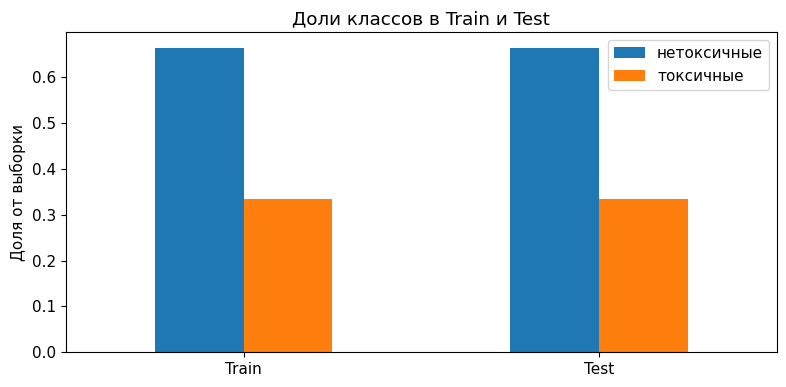

In [11]:
class_balance = pd.DataFrame({
    'Train': train_df['toxic'].value_counts(normalize=True),
    'Test': test_df['toxic'].value_counts(normalize=True),
}).sort_index()
class_balance.index = ['нетоксичные', 'токсичные']
display((class_balance * 100).round(2))
class_balance.T.plot.bar(figsize=(8, 4), rot=0, title='Доли классов в Train и Test')
plt.ylabel('Доля от выборки')
plt.tight_layout(); plt.show()

# 2. Исследование обучающей выборки

Измеряем число документов, длину в символах и словах, строим распределения. 

Документов в Train: 11529
Средняя длина (символы): 176.71
Средняя длина (слова): 27.34


,count,mean,std,min,25%,50%,75%,90%,95%,99%,max
len_chars,11529.0,176.705352,268.812163,21.0,57.0,102.0,198.0,367.2,526.0,1232.00,7404.0
len_words,11529.0,27.340446,39.829397,1.0,9.0,16.0,31.0,58.0,81.0,174.72,1033.0


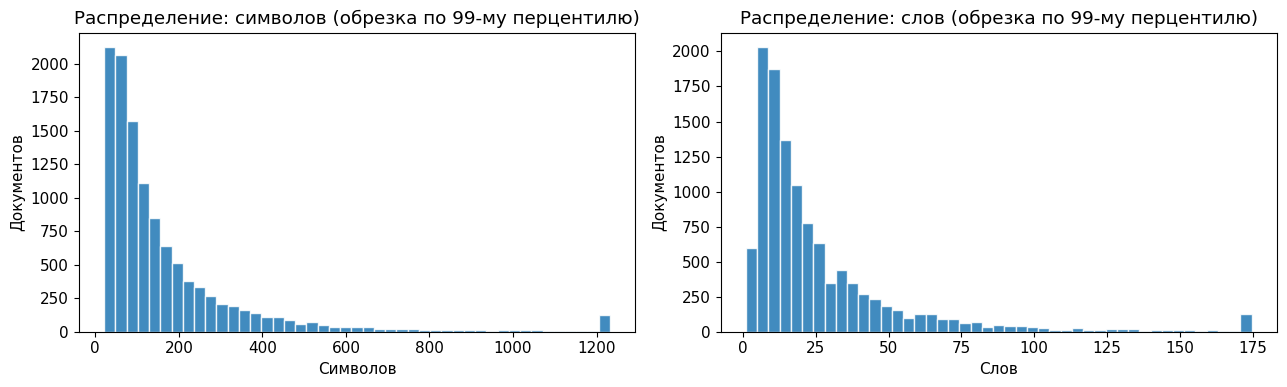

In [12]:

word_pattern = re.compile(r"[а-яёa-z]+(?:[-’'][а-яёa-z]+)*", flags=re.I)
train_df["len_chars"] = train_df["comment"].str.len()
train_df["len_words"] = train_df["comment"].map(lambda s: len(word_pattern.findall(s)))

print("Документов в Train:", len(train_df))
print("Средняя длина (символы):", round(train_df["len_chars"].mean(), 2))
print("Средняя длина (слова):", round(train_df["len_words"].mean(), 2))
display(train_df[["len_chars", "len_words"]].describe(percentiles=[.25, .5, .75, .9, .95, .99]).T)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, (col, name) in zip(axes, [("len_chars", "Символов"), ("len_words", "Слов")]):
    clipped = train_df[col].clip(upper=train_df[col].quantile(.99))
    ax.hist(clipped, bins=45, edgecolor="white", alpha=.85)
    ax.set(title=f"Распределение: {name.lower()} (обрезка по 99-му перцентилю)", xlabel=name, ylabel="Документов")
plt.tight_layout()
plt.show()

### Частоты стоп-слов

Стоп-слова считаем в исходном Train, **до** нормализации, чтобы показать, какие функциональные слова преобладают в комментариях.

Стоп-слова: NLTK
Всего различных стоп-слов из списка найдено: 151


,стоп-слово,частота
0,и,10176
1,в,9598
2,не,8200
3,на,5602
4,что,4509
5,а,3996
6,с,3435
7,как,2500
8,я,2497
9,у,2360


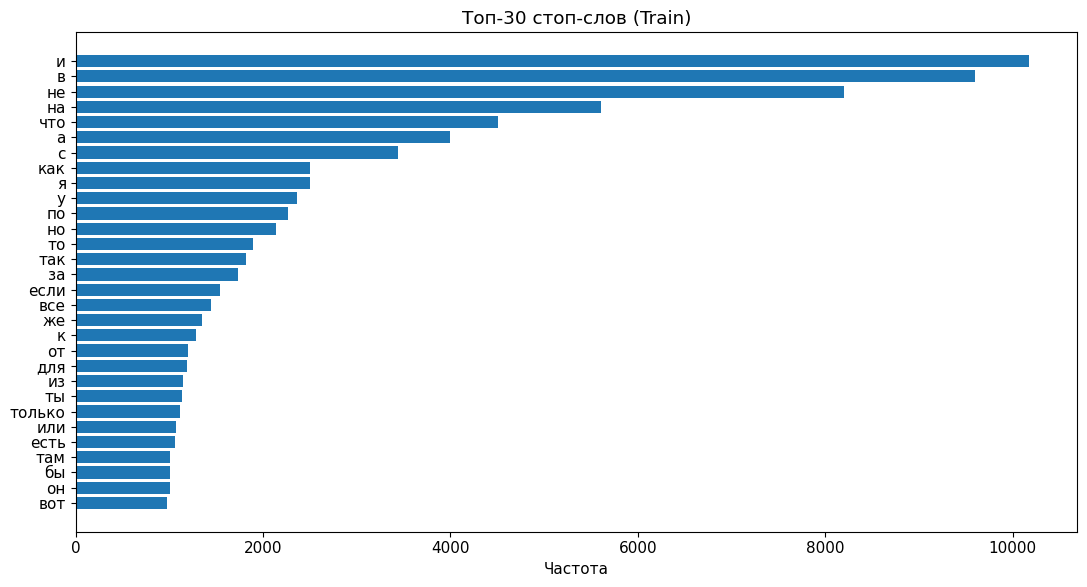

In [13]:
FALLBACK_STOPWORDS = set("""
и в во не что он на я с со как а то все она так его но да ты к у же вы за бы по только ее
мне было вот от меня еще нет о из ему теперь когда даже ну вдруг ли если уже или ни быть
был него до вас нибудь опять уж вам ведь там потом себя ничего ей может они тут где есть
надо ней для мы тебя их чем была сам чтоб без будто чего раз тоже себе под будет ж тогда
кто этот того потому этого какой совсем ним здесь этом один почти мой тем чтобы нее сейчас
были куда зачем всех никогда можно при наконец два об другой хоть после над больше тот
через эти нас про всего них какая много разве три эту моя впрочем хорошо свою этой перед
иногда лучше чуть том нельзя такой им более всегда конечно всю между очень где-то давай
ещё всё моё твой нашу наш ваш ваше себя тебя свой это этим ей него их ими кто-то тогда-то
""".split())
try:
    from nltk.corpus import stopwords
    RU_STOPWORDS = set(stopwords.words("russian"))
    print("Стоп-слова: NLTK")
except LookupError:
    RU_STOPWORDS = FALLBACK_STOPWORDS
    print("Стоп-слова: встроенный резервный список")

train_word_counts = Counter(
    w.lower() for s in train_df["comment"] for w in word_pattern.findall(s)
)
stop_top30 = [(word, freq) for word, freq in train_word_counts.most_common() if word in RU_STOPWORDS][:30]
print("Всего различных стоп-слов из списка найдено:", len(set(train_word_counts) & RU_STOPWORDS))
display(pd.DataFrame(stop_top30, columns=["стоп-слово", "частота"]))
if stop_top30:
    x, y = zip(*stop_top30)
    plt.figure(figsize=(11, 6))
    plt.barh(x[::-1], y[::-1]); plt.title("Топ-30 стоп-слов (Train)")
    plt.xlabel("Частота"); plt.tight_layout(); plt.show()

In [14]:
print('Медианная длина (слов):', round(train_df['len_words'].median(), 1))
print('90-й перцентиль длины (слов):', round(train_df['len_words'].quantile(.9), 1))
print('Наиболее частое стоп-слово:', stop_top30[0] if stop_top30 else 'не обнаружено')

Медианная длина (слов): 16.0
90-й перцентиль длины (слов): 58.0
Наиболее частое стоп-слово: ('и', 10176)


# 3. Анализ шума в русских комментариях


In [15]:

URL_RE = re.compile(r"(?i)\b(?:https?://|www\.)[^\s<>]+")
USER_RE = re.compile(r"(?<!\w)@[\w.-]{2,}", flags=re.U)
HTML_RE = re.compile(r"</?\w+(?:\s+[^<>]*)?>|&(?:#\d+|[a-z]{2,8});", flags=re.I)
EMOJI_RE = re.compile(r"[\U0001F300-\U0001FAFF\u2600-\u27BF]")
SMILE_RE = re.compile(r"(?<!\w)(?:[:;=]-?[()DPp]|\){3,}|\({3,})(?!\w)")
NUMBER_RE = re.compile(r"(?<!\w)\d+(?:[.,]\d+)*(?!\w)")
REPEAT_PUNCT_RE = re.compile(r"[!?.,]{3,}")
REPEAT_LETTERS_RE = re.compile(r"(?i)([а-яё])\1{3,}")
noise_rules = {
    "URL": URL_RE, "@упоминания": USER_RE, "HTML и сущности": HTML_RE,
    "Unicode-эмодзи": EMOJI_RE, "ASCII-смайлы": SMILE_RE,
    "числа": NUMBER_RE, "повторяющаяся пунктуация": REPEAT_PUNCT_RE,
    "повтор букв (эмфаза)": REPEAT_LETTERS_RE,
}
noise_rows = []
for name, pattern in noise_rules.items():
    hits = train_df["comment"].map(lambda s: bool(pattern.search(s)))
    examples = [pattern.search(s).group() for s in train_df.loc[hits, "comment"].head(3)]
    noise_rows.append({"тип шума": name, "документов": int(hits.sum()),
                       "доля, %": round(100 * hits.mean(), 2), "фрагменты": examples})
noise_report = pd.DataFrame(noise_rows)
display(noise_report)
print("Подтверждённых типов шума:", (noise_report["документов"] > 0).sum())

,тип шума,документов,"доля, %",фрагменты
0,URL,5,0.04,"[www.aspd.ru, www.youtube.com, www.garant.ru]"
1,@упоминания,0,0.00,[]
2,HTML и сущности,0,0.00,[]
3,Unicode-эмодзи,0,0.00,[]
4,ASCII-смайлы,32,0.28,"[:), :-), :-)]"
5,числа,2463,21.36,"[30, 150, 5]"
6,повторяющаяся пунктуация,892,7.74,"[..., ..., ...]"
7,повтор букв (эмфаза),77,0.67,"[ААААААААААААА, оооооооооо, Аааааа]"


Подтверждённых типов шума: 5


In [16]:
for noise_name, rx in noise_rules.items():
    matched = train_df.loc[train_df['comment'].map(lambda t: bool(rx.search(t))), 'comment']
    if len(matched) == 0:
        print(f'{noise_name}: в Train не найден')
        continue
    sample_text = matched.iloc[0].replace('\n', ' ')
    print(f'{noise_name}: {sample_text[:180]}')

URL: http: www.aspd.ru napravlenija dejatelnosti akusticheskie-materialy akusticheskaja rezina gsp 100 vibrozaschita 
@упоминания: в Train не найден
HTML и сущности: в Train не найден
Unicode-эмодзи: в Train не найден
ASCII-смайлы: Сленг помоек и знать не особо хочется :)
числа: Езжу каждый день. За этот год почти 30 тыс. 
повторяющаяся пунктуация: В начале нулевых, выписывал журнал, что то типо наука и техника там была статья что ученые смогли вырастить зубы у мышей и собак. Типо укол в десны, подсаживают типо зародыша зуба,
повтор букв (эмфаза): РЯ ЛАХТА ВЕЗДЕ ЛАХТА ПОД КРОВАТЬЮ У МЕНЯ ЛАХТА ААААААААААААА 


**Интерпретация:** наличие, отсутствие и доля каждого типа шума подтверждаются таблицей. При обработке токсичных сообщений нельзя механически удалять всю небуквенную информацию: повтор пунктуации и эмодзи могут передавать эмоциональную окраску.

# 4. Предобработка регулярными выражениями

Порядок операций: декодирование HTML → обработка HTML-тегов → замена URL и упоминаний → замена смайлов и чисел → сведение повторов букв и пунктуации → токенизация → границы `<s>` и `</s>`.

In [17]:
TOKEN_RE = re.compile(r"\[(?:URL|USER|NUM|EMOJI|UNK)\]|[а-яёa-z]+(?:[-'][а-яёa-z]+)*|[.!?]", re.I)


def clean_tokens(text: str):
    text = html.unescape(str(text)).lower().replace("’", "'")
    text = HTML_RE.sub(" ", text)
    text = URL_RE.sub(" [URL] ", text)
    text = USER_RE.sub(" [USER] ", text)
    text = EMOJI_RE.sub(" [EMOJI] ", text)
    text = SMILE_RE.sub(" [EMOJI] ", text)
    text = NUMBER_RE.sub(" [NUM] ", text)
    text = REPEAT_LETTERS_RE.sub(lambda m: m.group(1) * 2, text)
    text = re.sub(r"([.!?])\1{1,}", r"\1", text)
    tokens = TOKEN_RE.findall(text)
    tokens = [t.upper() if t.lower() in ("[url]", "[user]", "[num]", "[emoji]", "[unk]")
              else t for t in tokens]
    return ["<s>", *tokens, "</s>"]

checks = [
    "<b>ЗДРАВСТВУЙ</b>, @user! Смотри https://example.org/x?i=99 😊 123!!!",
    "Ужжжжасно, но комментарий-то хороший!!!",
]
for sample in checks:
    print("ИСХОДНЫЙ:", sample)
    print("ТОКЕНЫ:  ", clean_tokens(sample))
    print()
assert clean_tokens("@user https://example.org/test 42") == ["<s>", "[USER]", "[URL]", "[NUM]", "</s>"]
assert clean_tokens("Привет!")[0] == "<s>"
assert clean_tokens("Привет!")[-1] == "</s>"

ИСХОДНЫЙ: <b>ЗДРАВСТВУЙ</b>, @user! Смотри https://example.org/x?i=99 😊 123!!!
ТОКЕНЫ:   ['<s>', 'здравствуй', '[USER]', '!', 'смотри', '[URL]', '[EMOJI]', '[NUM]', '!', '</s>']

ИСХОДНЫЙ: Ужжжжасно, но комментарий-то хороший!!!
ТОКЕНЫ:   ['<s>', 'ужжасно', 'но', 'комментарий-то', 'хороший', '!', '</s>']



In [18]:
train_seq = train_df["comment"].map(clean_tokens).tolist()
test_seq = test_df["comment"].map(clean_tokens).tolist()  # Только для итогового тестирования LM
print("Пример исходного комментария:", train_df.loc[0, "comment"][:350])
print("После очистки:", " ".join(train_seq[0][:80]))
print("Примеры последовательностей с техническими границами:")
for seq in train_seq[:3]:
    print(" ".join(seq[:30]))

Пример исходного комментария: Вы читали закон о банкротстве? Что бы объявить банкротом нужно обратиться в Арбитражный суд с соответствующим заявлением, далее суд потребует внести на свой депозит сумму, обычно не менее 300т.р для обеспечения выплат арбитражному управляющему, если сумма не вносится, то в возбуждение дела о банкротстве откажут. Поэтому надо подавать в суд, затем и
После очистки: <s> вы читали закон о банкротстве ? что бы объявить банкротом нужно обратиться в арбитражный суд с соответствующим заявлением далее суд потребует внести на свой депозит сумму обычно не менее т . р для обеспечения выплат арбитражному управляющему если сумма не вносится то в возбуждение дела о банкротстве откажут . поэтому надо подавать в суд затем исполнительный лист приставам и требовать наложение ареста на расчетный счет и если повезет то появившиеся на счету деньги перечислят истцу . </s>
Примеры последовательностей с техническими границами:
<s> вы читали закон о банкротстве ? что бы объявить ба

In [19]:
show_ids = list(train_df.groupby('toxic', sort=True).head(3).index)
comparison = pd.DataFrame({
    'класс': train_df.loc[show_ids, 'toxic'].to_list(),
    'до очистки': train_df.loc[show_ids, 'comment'].str.slice(0, 190).to_list(),
    'после очистки': [' '.join(train_seq[i][:60]) for i in show_ids],
})
display(comparison)
print('Длина очищенного комментария (токенов):', len(train_seq[0]))
assert all(s[0] == '<s>' and s[-1] == '</s>' for s in train_seq[:100])

,класс,до очистки,после очистки
0,0,Вы читали закон о банкротстве? Что бы объявить...,<s> вы читали закон о банкротстве ? что бы объ...
1,0,а у сяоми это постоянно,<s> а у сяоми это постоянно </s>
2,1,"Хотел занять? Тогда да,проще позвонить , чем у...",<s> хотел занять ? тогда да проще позвонить че...
3,0,"заработки были без работы даже небольшие, но б...",<s> заработки были без работы даже небольшие н...
4,1,"Ну он по делу говорит, что такого? хохлоайтишн...",<s> ну он по делу говорит что такого ? хохлоай...
5,1,"Чернильницу ебнули, найс\n",<s> чернильницу ебнули найс </s>


Длина очищенного комментария (токенов): 78


## Сохранение результатов для ноутбуков 2 и 3

Очищенные тексты сохраняются вместе с исходным комментарием и классом. Это позволяет следующим ноутбукам использовать **тот же самый Train/Test split**, не загружать и не делить датасет повторно.

In [20]:
from pathlib import Path

ARTIFACTS_DIR = Path("artifacts")
ARTIFACTS_DIR.mkdir(parents=True, exist_ok=True)

train_df = train_df.copy()
test_df = test_df.copy()
train_df["comment_clean"] = [" ".join(tokens) for tokens in train_seq]
test_df["comment_clean"] = [" ".join(tokens) for tokens in test_seq]

train_path = ARTIFACTS_DIR / "train_clean.csv"
test_path = ARTIFACTS_DIR / "test_clean.csv"
train_df[["comment", "toxic", "comment_clean"]].to_csv(train_path, index=False, encoding="utf-8")
test_df[["comment", "toxic", "comment_clean"]].to_csv(test_path, index=False, encoding="utf-8")

eda_summary = pd.DataFrame([
    ("Объём Train", len(train_df)),
    ("Объём Test", len(test_df)),
    ("Средняя длина Train, слов", round(train_df["len_words"].mean(), 2)),
    ("Средняя длина Train, символов", round(train_df["len_chars"].mean(), 2)),
    ("Типов шума, обнаруженных в Train", int((noise_report["документов"] > 0).sum())),
], columns=["Показатель", "Значение"])
eda_summary.to_csv(ARTIFACTS_DIR / "eda_summary.csv", index=False, encoding="utf-8")

print("Сохранено:")
print(" ", train_path.resolve())
print(" ", test_path.resolve())
print("  ", (ARTIFACTS_DIR / "eda_summary.csv").resolve())
display(eda_summary)
assert train_df["comment_clean"].str.startswith("<s>").all()
assert train_df["comment_clean"].str.endswith("</s>").all()

Сохранено:
  D:\ITMO\itmo_text_analysis_toxic_lab1_v4\lab1\artifacts\train_clean.csv
  D:\ITMO\itmo_text_analysis_toxic_lab1_v4\lab1\artifacts\test_clean.csv
   D:\ITMO\itmo_text_analysis_toxic_lab1_v4\lab1\artifacts\eda_summary.csv


,Показатель,Значение
0,Объём Train,11529.00
1,Объём Test,2883.00
2,"Средняя длина Train, слов",27.34
3,"Средняя длина Train, символов",176.71
4,"Типов шума, обнаруженных в Train",5.00
